# SmartHydro sensor-log analysis

**Purpose.** 

This notebook describes the environmental conditions in the hydroponic tent during the usability tests. The sensor data is used **only to describe the testing environment**. It is not an input to the YOLOv8n model or the Android application, and it is not used to answer the research questions.

**Approach.**

 The raw export from the SmartHydro logging system is 
 
 1.  Loaded and renamed
 
 2.  Converted from UTC to South African Standard Time
 
 3.  Checked for missing values, duplicates and a second device
 
 4.  Labelled *ok*, *suspect* or *fault*
 
 5.  Summarised with descriptive statistics for the whole export and for the test session (23 October 2026, 11:30–12:05)
 
 6.  Plotted. Readings are **flagged rather than deleted**, so that no data is lost, and only readings labelled *ok* are summarised.

## **Imports**  

1. Pandas stores the readings in a table  and performs the cleaning, time conversion and statistics. 

2. matplotlib.pyplot draws the final figure. No other libraries are needed.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

pd.read_excel() reads the SmartHydro export into the DataFrame raw. 

The shape is (12711, 14)  means 12,711 tows and 14 columns. 

In [3]:
raw = pd.read_excel("SmartHydro Realtime Telemetry_.xlsx")
print(raw.shape)

(12711, 14)


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12711 entries, 0 to 12710
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ID                    12711 non-null  int64  
 1   Device MAC            12711 non-null  str    
 2   pH Level              12711 non-null  float64
 3   EC (mS/cm)            12711 non-null  float64
 4   Light (lux)           12711 non-null  int64  
 5   Water Level Raw       12711 non-null  int64  
 6   Water Level Detected  12711 non-null  bool   
 7   Temperature (°C)      12711 non-null  float64
 8   Humidity (%)          12711 non-null  float64
 9   ML pH Pred            12711 non-null  int64  
 10  ML EC Pred            12711 non-null  int64  
 11  ML Temp Pred          12711 non-null  int64  
 12  ML Humidity Pred      12711 non-null  int64  
 13  Recorded At (UTC)     12711 non-null  str    
dtypes: bool(1), float64(4), int64(7), str(2)
memory usage: 1.3 MB


All 14 columns have 12,711 non-null entries, so nothing is missing. Two points matter for later steps. Recorded At (UTC) is stored as text, so it cannot be used for time calculations until it is converted
Water Level Detected is a Boolean

In [5]:
# Rename coloumn names
df = raw.rename(columns={
    "Device MAC": "device", 
    "pH Level": "ph", 
    "EC (mS/cm)": "ec",
    "Light (lux)": "light", 
    "Temperature (°C)": "temp",
    "Humidity (%)": "rh", 
    "Recorded At (UTC)": "time_utc"})


The original headers contain spaces, units and brackets, which are error-prone to type. rename() gives the analysed columns short names 

In [ ]:
#(GeeksforGeeks, 2025c)

df["time_utc"] = pd.to_datetime(
    df["time_utc"].str.replace(r"\+00$", "+00:00", regex=True),
    utc=True, format="ISO8601")

The time column was imported as text. pd.to_datetime() converts text into pandas' datetime type (GeeksforGeeks, 2025c)

In [ ]:
#(GeeksforGeeks, 2024)
df["time"] = df["time_utc"].dt.tz_convert("Africa/Johannesburg")

The tests were run in South Africa, so the readings are converted from UTC to Africa/Johannesburg (South African Standard Time, UTC+2). tz_convert() converts a datetime to a target timezone (GeeksforGeeks, 2024). That is why utc=True was applied in the previous step. Conversion changes only how the clock time is displayed, and the underlying instant stays the same.


In [8]:
df = df.sort_values("time").reset_index(drop=True)

The sort_values("time") orders the rows by local time and reset_index(drop=True) renumbers them from 0. Ordering matters because the sampling-interval check later uses diff(), which only means something when neighbouring rows are consecutive in time.


In [9]:
print(df[[
    "ph",
    "ec",
    "light",
    "temp",
    "rh",
    "time"]].isna().sum())

ph       0
ec       0
light    0
temp     0
rh       0
time     0
dtype: int64


The isna().sum() counts empty cells in the different coloumns. Every count is 0, so no filling in values or row removal is needed.


In [10]:
print("Duplicates:", df.duplicated(subset=["device","time_utc"]).sum())

Duplicates: 0


A duplicate is defined as the same device logging the same UTC timestamp twice. The result is 0, so the export contains no repeated readings.


In [11]:
df = df.drop_duplicates(subset=["device","time_utc"])

In [12]:
print(df["device"].value_counts())

device
FC:01:2C:EE:29:F0    12693
10:51:DB:29:3F:0C       18
Name: count, dtype: int64


In [13]:
main_device = df["device"].value_counts().idxmax()

Pick the device with the most readings as the main one.

In [14]:
df = df[df["device"] == main_device].copy()

In [15]:
df["quality"] = "ok"

Labels every reading "ok" to start. Bad readings are labelled in the next steps, not deleted.


In [16]:
df.loc[(df["ph"] >= 14) | (df["ec"] < 0.5), "quality"] = "fault"

Labels readings "fault" if pH is 14 or above or EC is below 0.5, because these values are not realistic.


In [17]:
df.loc[df["ph"] > 7.5, "quality"] = "suspect" 

Labels readings "suspect" if pH is above 7.5. This marks the setup period before the pH was corrected. This rule runs after the fault rule, so it would overwrite a pH of 14 or above.


In [18]:
print(df["quality"].value_counts())

quality
ok         12656
suspect       37
Name: count, dtype: int64


12,656 readings are "ok" and 37 are "suspect". Only "ok" readings are used from here on.

In [19]:
df["gap_s"] = df["time"].diff().dt.total_seconds()

In [ ]:
print("Median interval:", df["gap_s"].median(), " gaps > 120 s:", (df["gap_s"] > 120).sum())

Median interval: 29.2725 | gaps > 120 s: 0


Readings are about 29 seconds apart and no gap is longer than 120 seconds, so the record is continuous.


In [21]:
ok = df[df["quality"] == "ok"]

In [22]:
cols = ["ph", "ec", "temp", "rh", "light"]

In [23]:
print(ok[cols].agg(["count","mean","std","min","max"]).T.round(2))

         count    mean     std    min     max
ph     12656.0    6.22    0.05   6.13    6.51
ec     12656.0    2.77    0.01   2.74    2.80
temp   12656.0   24.88    4.29  19.09   37.15
rh     12656.0   68.48    6.95  48.32   78.26
light  12656.0  191.75  229.42   0.00  524.00


In [24]:
start = pd.Timestamp("2026-10-23 11:30", tz="Africa/Johannesburg")

In [25]:
end   = pd.Timestamp("2026-10-23 12:05", tz="Africa/Johannesburg")


In [26]:
session = ok[(ok["time"] >= start) & (ok["time"] <= end)]

In [27]:
table = session[cols].agg(["count","mean","std","min","max"]).T.round(2)
print(table)

       count    mean    std     min     max
ph      72.0    6.26   0.01    6.23    6.28
ec      72.0    2.75   0.00    2.75    2.75
temp    72.0   31.09   0.22   30.64   31.54
rh      72.0   58.47   0.42   57.42   59.54
light   72.0  505.07  10.65  488.00  523.00


In [28]:
day = ok[ok["time"].dt.date == pd.Timestamp("2026-10-23").date()]
print(day.groupby(day["time"].dt.hour)[cols].mean().round(2))

        ph    ec   temp     rh   light
time                                  
0     6.24  2.78  21.35  74.19    0.00
1     6.24  2.78  21.12  74.54    0.00
2     6.23  2.77  20.95  74.82    0.00
3     6.23  2.77  20.80  75.10    0.00
4     6.22  2.77  20.68  75.26    0.00
5     6.23  2.78  20.06  76.27    0.00
6     6.25  2.78  20.60  75.44  506.74
7     6.25  2.78  22.16  72.86  506.25
8     6.25  2.78  24.30  69.40  505.72
9     6.26  2.78  26.70  65.52  506.24
10    6.25  2.76  28.95  61.90  506.54
11    6.26  2.75  30.70  59.07  505.36
12    6.24  2.75  31.65  57.54  506.57
13    6.23  2.74  31.59  57.61  504.66
14    6.23  2.74  30.41  59.50   54.67
15    6.24  2.74  28.39  62.79  100.47
16    6.25  2.75  26.13  66.43  113.88
17    6.24  2.75  24.30  69.45   90.75
18    6.24  2.75  23.38  70.94   35.50
19    6.23  2.74  22.94  71.62    0.00
20    6.21  2.75  22.52  72.31    0.00
21    6.20  2.74  22.17  72.84    0.00
22    6.21  2.75  21.85  73.39    0.00
23    6.20  2.76  21.58  

Average per hour on 23 October. The test took place at midday, the warmest, driest and brightest time of the day.

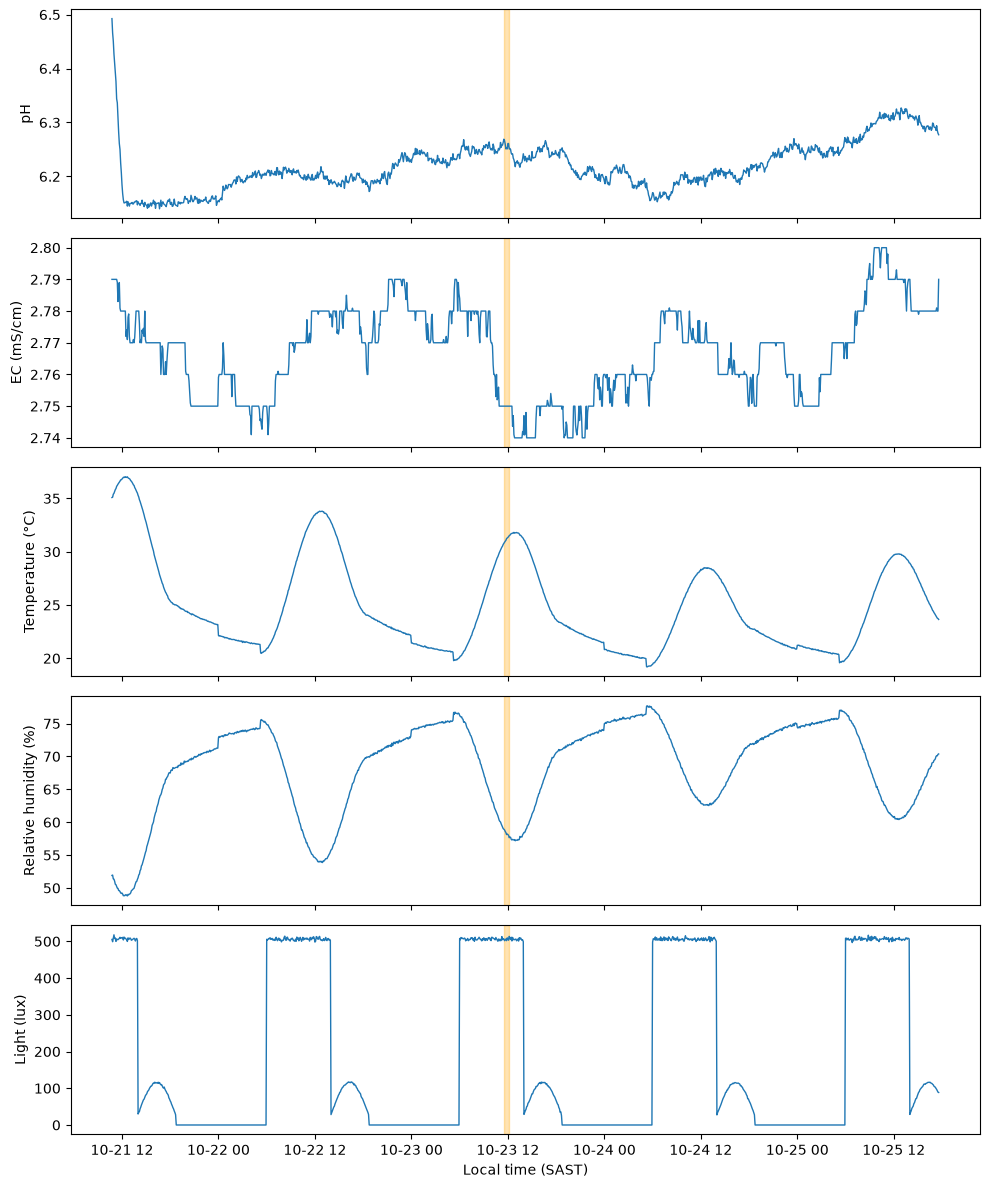

In [ ]:
five = ok.set_index("time")[cols].resample("5min").mean()
labels = {"ph":"pH",
          "ec":"EC (mS/cm)",
          "temp":"Temperature (°C)",
          "rh":"Relative humidity (%)",
          "light":"Light (lux)"}
fig, axes = plt.subplots(5, 1, figsize=(10, 12), sharex=True)
# W3Schools, [s.a.].
# GeeksforGeeks, 2025b
for ax, c in zip(axes, cols):
    ax.plot(five.index, five[c], lw=1)
    ax.axvspan(start, end, color="orange", alpha=0.3)
    ax.set_ylabel(labels[c])
axes[-1].set_xlabel("Local time (SAST)")


plt.tight_layout(); 
#GeeksforGeeks, 2025a
plt.savefig("tent_conditions.png", dpi=200)

Plots the five variables as 5-minute averages, with the test session shaded in orange. plt.subplots() creates a grid of plots (GeeksforGeeks, 2025b). sharex=True gives them one shared time axis (GeeksforGeeks, 2025b). W3Schools ([s.a.]) shows the same idea with plt.subplot(). plt.savefig() saves the figure as an image (GeeksforGeeks, 2025a).

## References

GeeksforGeeks, 2024. *Pandas DataFrame.tz_convert*. [online] Available at: <https://www.geeksforgeeks.org/pandas/python-pandas-dataframe-tz_convert/> [Accessed 26 October 2026].

GeeksforGeeks, 2025a. *How to save a plot to a file using Matplotlib?* [online] Available at: <https://www.geeksforgeeks.org/python/how-to-save-a-plot-to-a-file-using-matplotlib/> [Accessed 26 October 2026].

GeeksforGeeks, 2025b. *Matplotlib subplots*. [online] Available at: <https://www.geeksforgeeks.org/python/matplotlib-pyplot-subplots-in-python/> [Accessed 26 October 2026].

GeeksforGeeks, 2025c. *Pandas.to_datetime()-Python*. [online] Available at: <https://www.geeksforgeeks.org/pandas/python-pandas-to_datetime/> [Accessed 26 October 2026].

W3Schools, [s.a.]. *Matplotlib subplot*. [online] Available at: <https://www.w3schools.com/python/matplotlib_subplot.asp> [Accessed 26 October 2026].